# MachineGuard — Feature Analysis

This notebook analyzes the engineered time-domain vibration features
extracted from NASA IMS Set 1, Bearing 4 X-axis.

The goal is to understand how each feature evolves over the run-to-failure
experiment before using the features for machine learning.

In [1]:
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt

In [2]:
file_path = Path("../data/processed/ims_set1_bearing4_x_features.csv")

features_df = pd.read_csv(
    file_path,
    parse_dates=["timestamp"],
)

In [3]:
features_df.head()

,rms,std,peak,crest_factor,kurtosis,dominant_frequency,spectral_energy,timestamp
0,0.109020,0.060085,0.413,3.788279,3.790250,986.328125,757118.612018,2003-10-22 12:06:24
1,0.108900,0.059420,0.420,3.856767,4.234703,986.328125,740448.654400,2003-10-22 12:09:13
2,0.110319,0.059968,0.396,3.589583,3.924708,986.328125,754376.681760,2003-10-22 12:14:13
3,0.111037,0.059915,0.393,3.539356,3.652667,986.328125,752875.194856,2003-10-22 12:19:13
4,0.110190,0.059255,0.376,3.412278,3.635576,986.328125,736347.011716,2003-10-22 12:24:13


In [4]:
features_df.dtypes

rms                          float64
std                          float64
peak                         float64
crest_factor                 float64
kurtosis                     float64
dominant_frequency           float64
spectral_energy              float64
timestamp             datetime64[us]
dtype: object

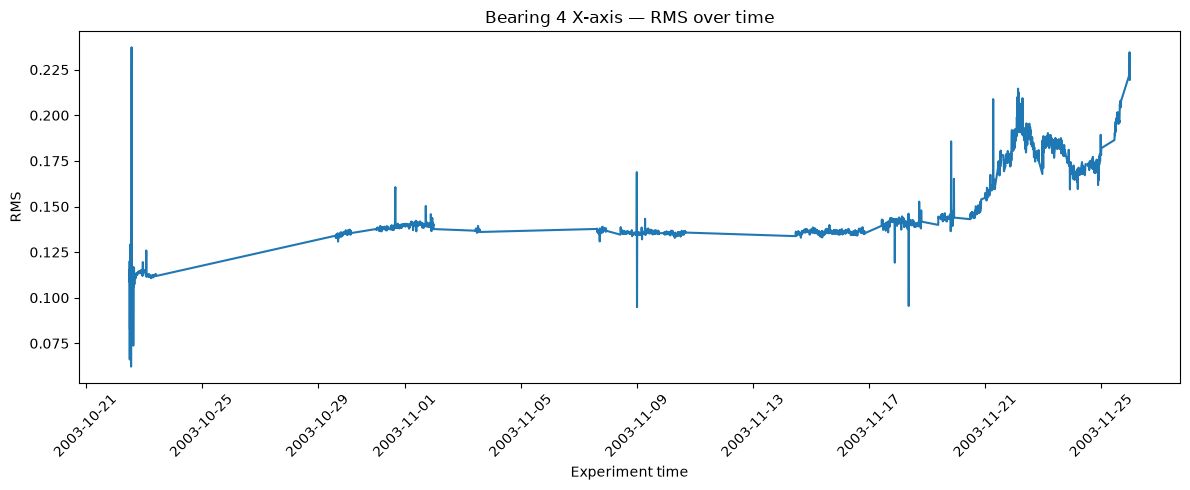

In [5]:
plt.figure(figsize=(12, 5))

plt.plot(
    features_df["timestamp"],
    features_df["rms"],
)

plt.xlabel("Experiment time")
plt.ylabel("RMS")
plt.title("Bearing 4 X-axis — RMS over time")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

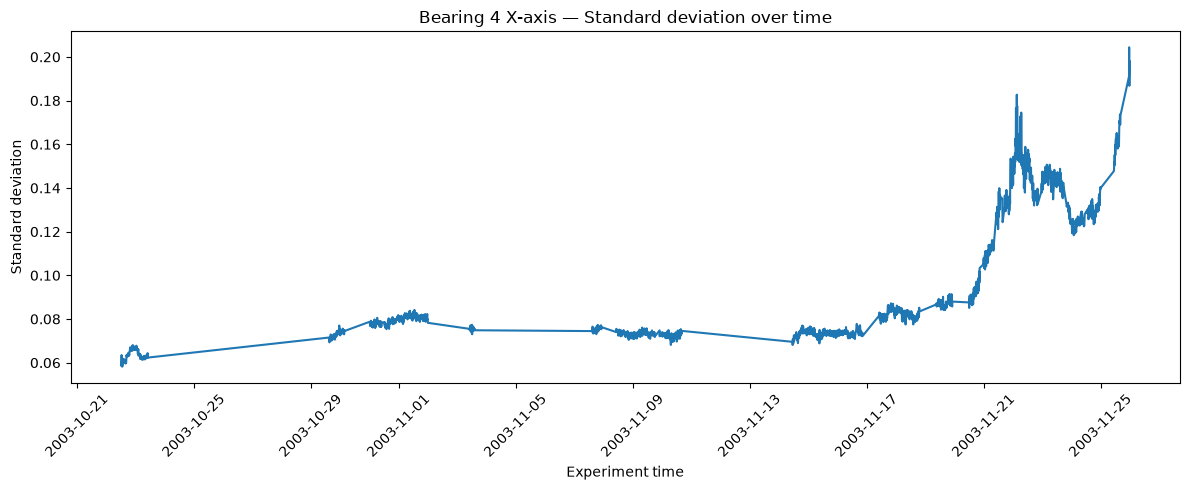

In [6]:
plt.figure(figsize=(12, 5))

plt.plot(
    features_df["timestamp"],
    features_df["std"],
)

plt.xlabel("Experiment time")
plt.ylabel("Standard deviation")
plt.title("Bearing 4 X-axis — Standard deviation over time")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

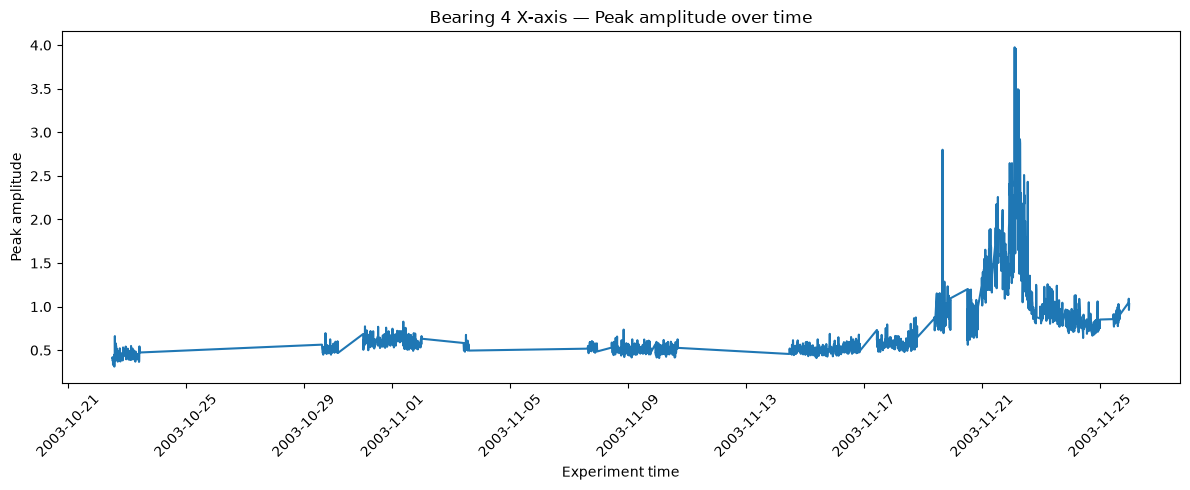

In [7]:
plt.figure(figsize=(12, 5))

plt.plot(
    features_df["timestamp"],
    features_df["peak"],
)

plt.xlabel("Experiment time")
plt.ylabel("Peak amplitude")
plt.title("Bearing 4 X-axis — Peak amplitude over time")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

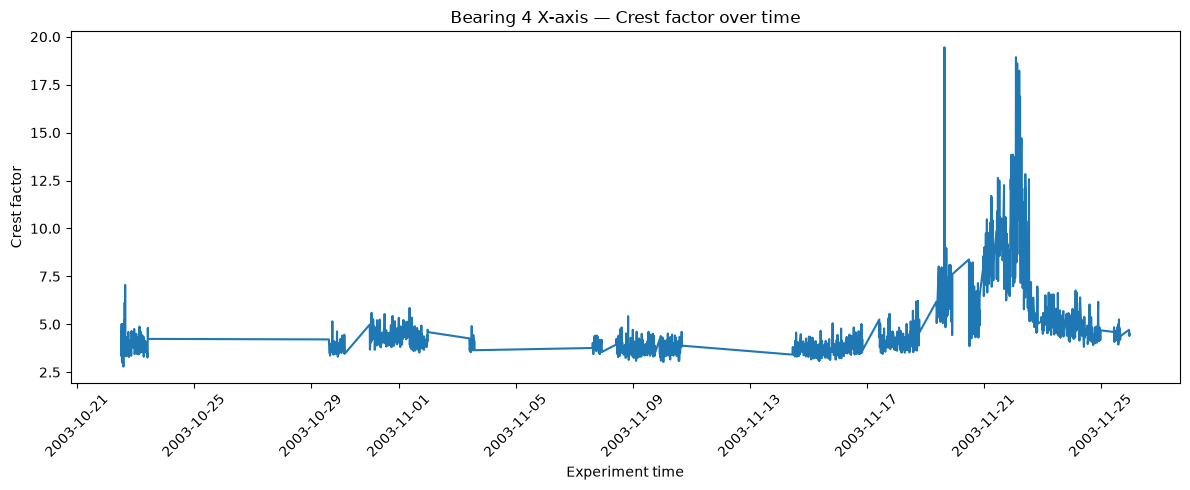

In [8]:
plt.figure(figsize=(12, 5))

plt.plot(
    features_df["timestamp"],
    features_df["crest_factor"],
)

plt.xlabel("Experiment time")
plt.ylabel("Crest factor")
plt.title("Bearing 4 X-axis — Crest factor over time")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

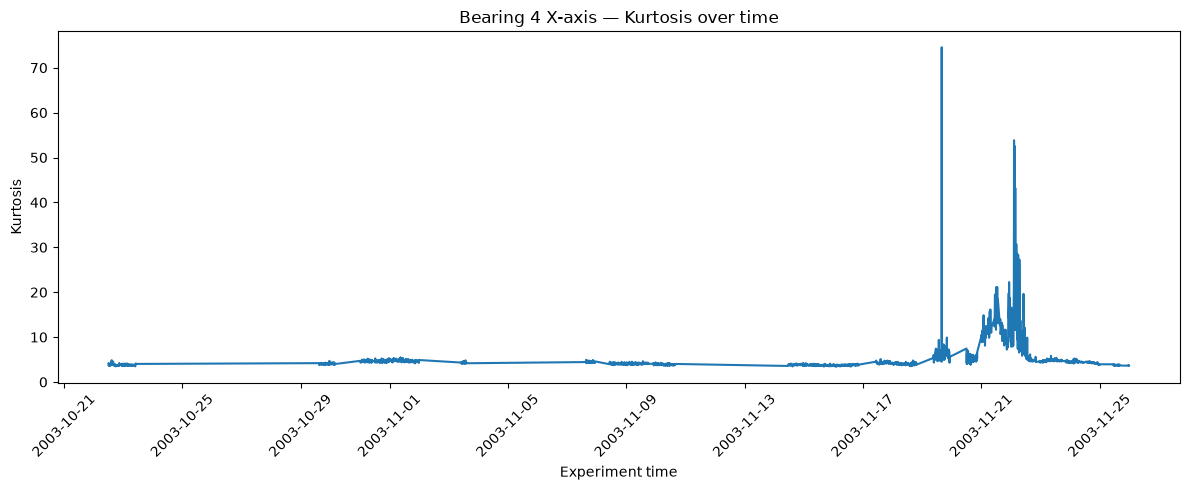

In [9]:
plt.figure(figsize=(12, 5))

plt.plot(
    features_df["timestamp"],
    features_df["kurtosis"],
)

plt.xlabel("Experiment time")
plt.ylabel("Kurtosis")
plt.title("Bearing 4 X-axis — Kurtosis over time")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [10]:
feature_columns = [
    "rms",
    "std",
    "peak",
    "crest_factor",
    "kurtosis",
]

correlation_matrix = features_df[feature_columns].corr()

correlation_matrix

,rms,std,peak,crest_factor,kurtosis
rms,1.000000,0.962075,0.716179,0.564714,0.405552
std,0.962075,1.000000,0.738759,0.603498,0.419878
peak,0.716179,0.738759,1.000000,0.973375,0.832505
crest_factor,0.564714,0.603498,0.973375,1.000000,0.858087
kurtosis,0.405552,0.419878,0.832505,0.858087,1.000000


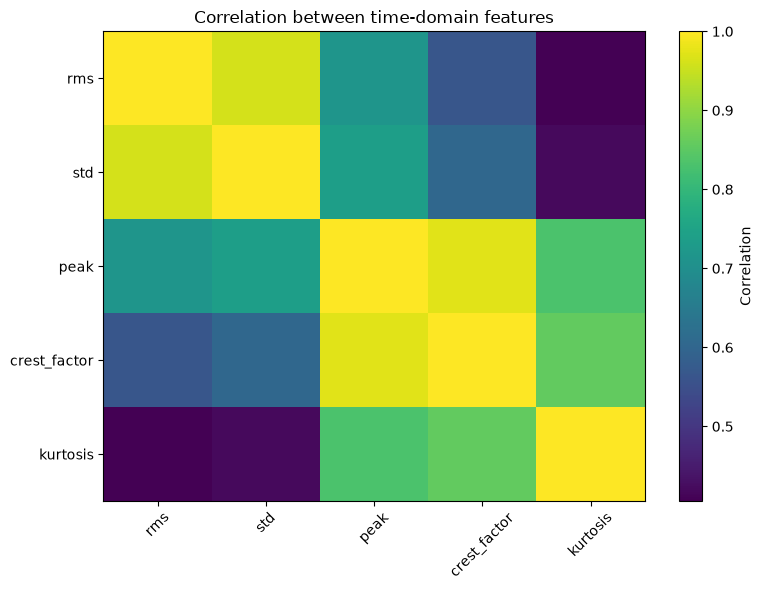

In [11]:
plt.figure(figsize=(8, 6))

plt.imshow(
    correlation_matrix,
    aspect="auto",
)

plt.colorbar(label="Correlation")

plt.xticks(
    range(len(feature_columns)),
    feature_columns,
    rotation=45,
)

plt.yticks(
    range(len(feature_columns)),
    feature_columns,
)

plt.title("Correlation between time-domain features")
plt.tight_layout()
plt.show()

## Conclusions

The time-domain features show a clear change in the vibration behavior of Bearing 4 as the experiment approaches failure.

- **RMS** remains relatively stable during most of the experiment and increases substantially near the end, indicating a higher overall vibration magnitude.
- **Standard deviation** shows a similar but cleaner increasing trend, indicating that the vibration signal becomes increasingly variable.
- **Peak amplitude** becomes much larger and more unstable near the end of the experiment, suggesting the presence of stronger individual vibration impacts.
- **Crest factor** increases sharply during the degradation phase, indicating that some vibration peaks become unusually large relative to the overall vibration level.
- **Kurtosis** shows very large spikes during the degradation period, suggesting increasingly impulsive and heavy-tailed vibration behavior.

The correlation analysis also shows that some features contain overlapping information. RMS and standard deviation are strongly correlated, while peak amplitude, crest factor, and kurtosis are strongly related to each other.

Overall, the features appear to capture two complementary aspects of bearing condition:

1. **Overall vibration intensity**, mainly represented by RMS and standard deviation.
2. **Impulsive or shock-like behavior**, mainly represented by peak amplitude, crest factor, and kurtosis.

All five features will be retained for the initial machine-learning experiments. Feature selection can be evaluated later based on model performance and interpretability.

# Frequency-Domain Analysis

The time-domain features describe the overall magnitude, variability, and impulsiveness of the vibration signal.

This section analyzes the same vibration data in the frequency domain using the Fast Fourier Transform (FFT), with the goal of identifying dominant frequencies and extracting spectral features.

In [12]:
import pandas as pd
import numpy as np

from machineguard.features.frequency_domain import compute_fft

In [13]:
raw_file = Path(
    "../data/raw/IMS/1st_test/2003.10.22.12.06.24"
)

snapshot = pd.read_csv(
    raw_file,
    sep="\t",
    header=None,
)

signal = snapshot.iloc[:, 6]

In [14]:
sampling_rate = 20_000

frequencies, amplitudes = compute_fft(
    signal,
    sampling_rate,
)

In [15]:
frequencies.shape

(10241,)

In [16]:
amplitudes.shape

(10241,)

In [17]:
frequencies[0]

np.float64(0.0)

In [18]:
frequencies[-1]

np.float64(10000.0)

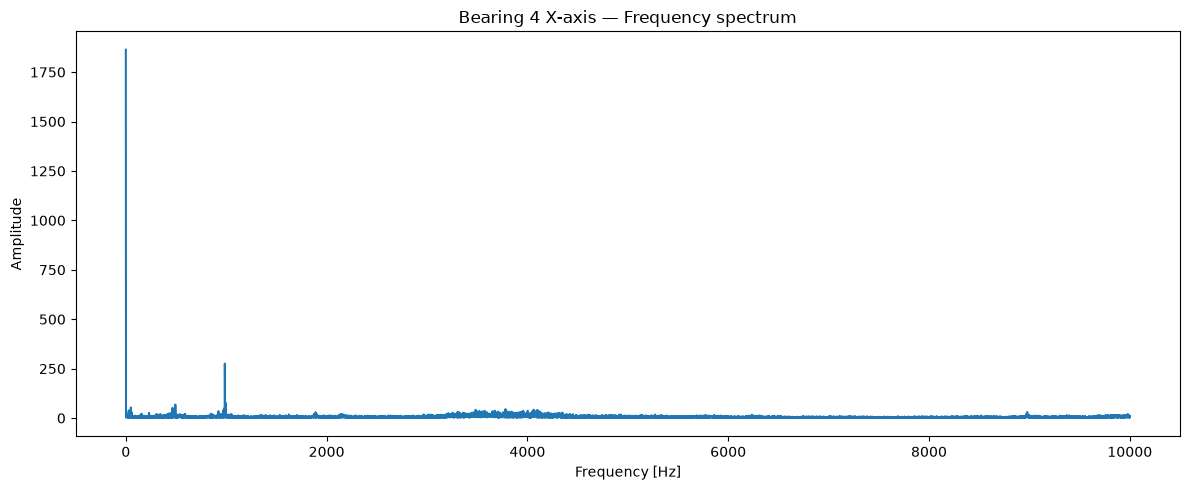

In [22]:
plt.figure(figsize=(12, 5))

plt.plot(
    frequencies,
    amplitudes,
)

plt.xlabel("Frequency [Hz]")
plt.ylabel("Amplitude")
plt.title("Bearing 4 X-axis — Frequency spectrum")

plt.tight_layout()
plt.show()

### Initial frequency spectrum

The FFT transforms the vibration signal from the time domain into the frequency domain.

In this spectrum, the large peak at 0 Hz corresponds to the DC component of the signal. This component is caused by the non-zero mean of the vibration measurements rather than by an oscillatory vibration frequency.

Since the goal is to analyze the vibration content of the bearing, the mean is removed from the signal before recomputing the spectrum. This reduces the DC component and makes the relevant vibration frequencies easier to inspect.

In [23]:
signal_centered = signal - np.mean(signal)